<a href="https://colab.research.google.com/github/Amyerm/ClassFiles/blob/main/%C3%81rbol_de_Decisi%C3%B3n_para_Regresi%C3%B3n.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Árboles de Regresión
### Actividad: Árbol de Decisión para Regresión
**Objetivo**
Analizar el comportamiento de un modelo de árbol de decisión en un problema de regresión, evaluando su capacidad de generalización mediante el estudio del sobreajuste, la profundidad del árbol y la poda.

**Módulo:** Dataset
Se utilizará el dataset California Housing, disponible en scikit-learn.
---


---
## 1. Carga y exploración de datos

In [ ]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.datasets import fetch_california_housing
from sklearn.model_selection import train_test_split
from sklearn.tree import DecisionTreeRegressor
from sklearn.metrics import mean_squared_error, r2_score

In [ ]:
# Carga del dataset
california = fetch_california_housing(as_frame=True)
df = california.frame
df.head()

,MedInc,HouseAge,AveRooms,AveBedrms,Population,AveOccup,Latitude,Longitude,MedHouseVal
0,8.3252,41.0,6.984127,1.023810,322.0,2.555556,37.88,-122.23,4.526
1,8.3014,21.0,6.238137,0.971880,2401.0,2.109842,37.86,-122.22,3.585
2,7.2574,52.0,8.288136,1.073446,496.0,2.802260,37.85,-122.24,3.521
3,5.6431,52.0,5.817352,1.073059,558.0,2.547945,37.85,-122.25,3.413
4,3.8462,52.0,6.281853,1.081081,565.0,2.181467,37.85,-122.25,3.422


In [ ]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 20640 entries, 0 to 20639
Data columns (total 9 columns):
 #   Column       Non-Null Count  Dtype  
---  ------       --------------  -----  
 0   MedInc       20640 non-null  float64
 1   HouseAge     20640 non-null  float64
 2   AveRooms     20640 non-null  float64
 3   AveBedrms    20640 non-null  float64
 4   Population   20640 non-null  float64
 5   AveOccup     20640 non-null  float64
 6   Latitude     20640 non-null  float64
 7   Longitude    20640 non-null  float64
 8   MedHouseVal  20640 non-null  float64
dtypes: float64(9)
memory usage: 1.4 MB


In [ ]:
df.describe()

,MedInc,HouseAge,AveRooms,AveBedrms,Population,AveOccup,Latitude,Longitude,MedHouseVal
count,20640.000000,20640.000000,20640.000000,20640.000000,20640.000000,20640.000000,20640.000000,20640.000000,20640.000000
mean,3.870671,28.639486,5.429000,1.096675,1425.476744,3.070655,35.631861,-119.569704,2.068558
std,1.899822,12.585558,2.474173,0.473911,1132.462122,10.386050,2.135952,2.003532,1.153956
min,0.499900,1.000000,0.846154,0.333333,3.000000,0.692308,32.540000,-124.350000,0.149990
25%,2.563400,18.000000,4.440716,1.006079,787.000000,2.429741,33.930000,-121.800000,1.196000
50%,3.534800,29.000000,5.229129,1.048780,1166.000000,2.818116,34.260000,-118.490000,1.797000
75%,4.743250,37.000000,6.052381,1.099526,1725.000000,3.282261,37.710000,-118.010000,2.647250
max,15.000100,52.000000,141.909091,34.066667,35682.000000,1243.333333,41.950000,-114.310000,5.000010


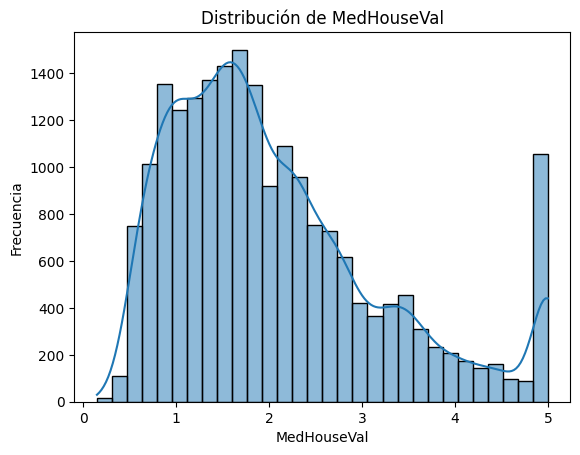

In [ ]:
sns.histplot(df["MedHouseVal"], bins=30, kde=True)

plt.title("Distribución de MedHouseVal")
plt.xlabel("MedHouseVal")
plt.ylabel("Frecuencia")

plt.show()

La variable MedHouseVal presenta una mayor concentración de valores aproximadamente entre 1 y 2.5. La distribución no es completamente simétrica y muestra una cola hacia los valores más altos. También se observa una concentración considerable de observaciones cerca del valor máximo de 5, por lo que la distribución presenta un comportamiento particular en ese extremo.

---
## 2. Preparación de datos

In [ ]:
# Preparación de datos

X = df.drop("MedHouseVal", axis=1)
y = df["MedHouseVal"]

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42
)

print("Entrenamiento:", X_train.shape)
print("Prueba:", X_test.shape)

Entrenamiento: (16512, 8)
Prueba: (4128, 8)


---
## 3. Modelo base

In [ ]:
# Modelo base sin restricciones

arbol_base = DecisionTreeRegressor(
    max_depth=None,
    random_state=42
)

arbol_base.fit(X_train, y_train)

# Predicciones
y_train_pred = arbol_base.predict(X_train)
y_test_pred = arbol_base.predict(X_test)

# Métricas de entrenamiento
rmse_train = np.sqrt(mean_squared_error(y_train, y_train_pred))
r2_train = r2_score(y_train, y_train_pred)

# Métricas de prueba
rmse_test = np.sqrt(mean_squared_error(y_test, y_test_pred))
r2_test = r2_score(y_test, y_test_pred)

print("Entrenamiento")
print("RMSE:", rmse_train)
print("R²:", r2_train)

print("\nPrueba")
print("RMSE:", rmse_test)
print("R²:", r2_test)

print("\nProfundidad del árbol:", arbol_base.get_depth())
print("Número de hojas:", arbol_base.get_n_leaves())

Entrenamiento
RMSE: 3.218325866275131e-16
R²: 1.0

Prueba
RMSE: 0.7037294974840077
R²: 0.622075845135081

Profundidad del árbol: 34
Número de hojas: 15854


El modelo base presenta sobreajuste. En los datos de entrenamiento obtiene un RMSE prácticamente igual a cero y un R² de 1, lo que indica que el árbol se ajusta casi perfectamente a esos datos. Sin embargo, en el conjunto de prueba el RMSE aumenta aproximadamente a 0.70 y el R² disminuye a 0.62. Además, el árbol alcanza una profundidad de 34 y tiene una gran cantidad de hojas, por lo que se volvió demasiado complejo y no generaliza igual de bien con datos nuevos.

---
## 4. Análisis Bias–Variance

In [ ]:
# Análisis Bias-Variance

profundidades = range(1, 22)

rmse_train_depth = []
rmse_test_depth = []

for profundidad in profundidades:
    arbol = DecisionTreeRegressor(
        max_depth=profundidad,
        random_state=42
    )

    arbol.fit(X_train, y_train)

    pred_train = arbol.predict(X_train)
    pred_test = arbol.predict(X_test)

    rmse_train_depth.append(
        np.sqrt(mean_squared_error(y_train, pred_train))
    )

    rmse_test_depth.append(
        np.sqrt(mean_squared_error(y_test, pred_test))
    )

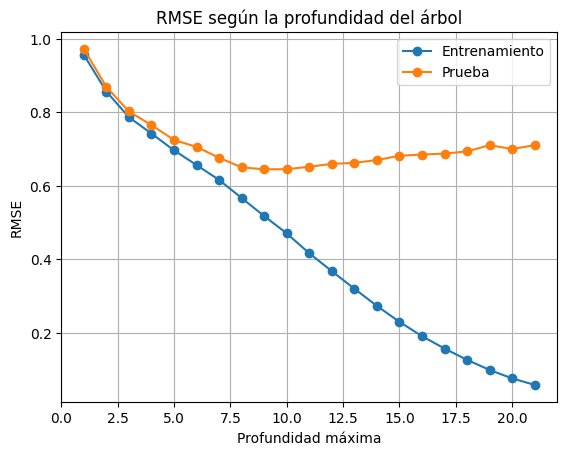

In [ ]:
plt.plot(profundidades, rmse_train_depth, marker="o", label="Entrenamiento")
plt.plot(profundidades, rmse_test_depth, marker="o", label="Prueba")

plt.xlabel("Profundidad máxima")
plt.ylabel("RMSE")
plt.title("RMSE según la profundidad del árbol")

plt.legend()
plt.grid()

plt.show()

In [ ]:
mejor_indice = np.argmin(rmse_test_depth)
mejor_profundidad = list(profundidades)[mejor_indice]
mejor_rmse = rmse_test_depth[mejor_indice]

print("Mejor profundidad:", mejor_profundidad)
print("RMSE de prueba:", mejor_rmse)

Mejor profundidad: 9
RMSE de prueba: 0.6442578164688181


Al aumentar la profundidad del árbol, el error de entrenamiento disminuye de forma continua porque el modelo se vuelve más complejo y se ajusta mejor a esos datos. En el conjunto de prueba, el RMSE disminuye hasta alcanzar su mejor valor con una profundidad de 9, donde es aproximadamente 0.644. Después de ese punto, el error de prueba comienza a aumentar mientras el error de entrenamiento sigue bajando, lo que indica que el modelo empieza a sobreajustarse. Por esta razón, una profundidad de 9 presenta el mejor equilibrio entre ajuste y generalización.

---
## 5. Poda del árbol

In [ ]:
# Obtener la ruta de poda

arbol_poda = DecisionTreeRegressor(
    random_state=42,
    max_depth=10
)

ruta = arbol_poda.cost_complexity_pruning_path(
    X_train,
    y_train
)

ccp_alphas = ruta.ccp_alphas

# Evaluar cada 5 valores
ccp_alphas = ccp_alphas[::5]

print("Cantidad de valores de ccp_alpha:", len(ccp_alphas))

Cantidad de valores de ccp_alpha: 140


In [ ]:
rmse_train_alpha = []
rmse_test_alpha = []

for alpha in ccp_alphas:
    arbol = DecisionTreeRegressor(
        random_state=42,
        max_depth=10,
        ccp_alpha=alpha
    )

    arbol.fit(X_train, y_train)

    pred_train = arbol.predict(X_train)
    pred_test = arbol.predict(X_test)

    rmse_train_alpha.append(
        np.sqrt(mean_squared_error(y_train, pred_train))
    )

    rmse_test_alpha.append(
        np.sqrt(mean_squared_error(y_test, pred_test))
    )

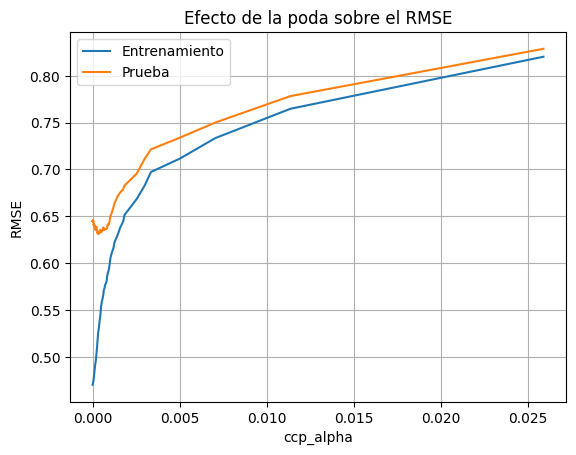

In [ ]:
plt.plot(ccp_alphas, rmse_train_alpha, label="Entrenamiento")
plt.plot(ccp_alphas, rmse_test_alpha, label="Prueba")

plt.xlabel("ccp_alpha")
plt.ylabel("RMSE")
plt.title("Efecto de la poda sobre el RMSE")

plt.legend()
plt.grid()
plt.show()

In [ ]:
mejor_indice_alpha = np.argmin(rmse_test_alpha)

mejor_alpha = ccp_alphas[mejor_indice_alpha]
mejor_rmse_alpha = rmse_test_alpha[mejor_indice_alpha]

print("Mejor ccp_alpha:", mejor_alpha)
print("Mejor RMSE de prueba:", mejor_rmse_alpha)

Mejor ccp_alpha: 0.00033998267401896907
Mejor RMSE de prueba: 0.6310728950726185


---
## 6. Interpretación de resultados

In [ ]:
# Importancia de las variables

arbol_mejor = DecisionTreeRegressor(
    max_depth=9,
    random_state=42
)

arbol_mejor.fit(X_train, y_train)

importancias = pd.DataFrame({
    "Variable": X.columns,
    "Importancia": arbol_mejor.feature_importances_
}).sort_values("Importancia", ascending=False)

importancias

,Variable,Importancia
0,MedInc,0.631555
5,AveOccup,0.131729
6,Latitude,0.075473
7,Longitude,0.058643
1,HouseAge,0.043700
2,AveRooms,0.036752
4,Population,0.011276
3,AveBedrms,0.010872


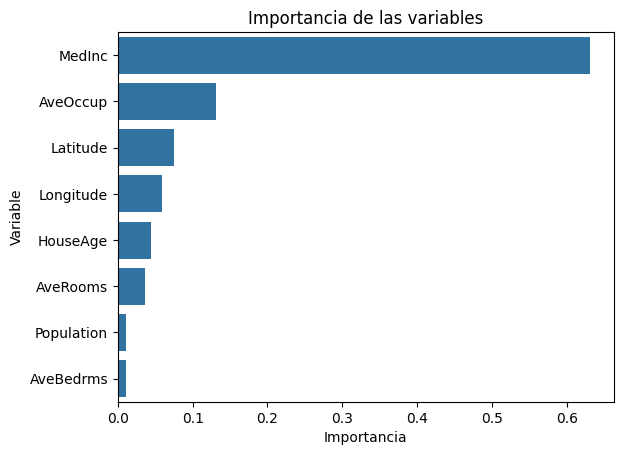

In [ ]:
sns.barplot(
    data=importancias,
    x="Importancia",
    y="Variable"
)

plt.title("Importancia de las variables")
plt.show()

**¿El modelo base presenta sobreajuste?**

Sí. El modelo base obtuvo un RMSE prácticamente igual a cero y un R² de 1 en entrenamiento, mientras que en prueba obtuvo un RMSE aproximado de 0.70 y un R² de 0.62. Además, el árbol alcanzó una profundidad de 34 y una gran cantidad de hojas. Esto indica que se ajustó demasiado a los datos de entrenamiento y no generaliza igual de bien con datos nuevos.

**¿Cómo afecta la profundidad del árbol al error?**

Al aumentar la profundidad, el error de entrenamiento disminuye porque el modelo se vuelve más complejo. En prueba, el RMSE disminuye hasta una profundidad de 9, donde alcanza aproximadamente 0.644. Después de ese punto el error de prueba comienza a aumentar mientras el de entrenamiento continúa disminuyendo.

**¿Qué efecto tiene la poda en el modelo?**

La poda reduce la complejidad del árbol eliminando ramas que aportan poca mejora. En este caso, una poda moderada permitió disminuir ligeramente el RMSE de prueba hasta aproximadamente 0.638. Sin embargo, al aumentar demasiado el valor de `ccp_alpha`, el error comienza a crecer tanto en entrenamiento como en prueba y una poda excesiva puede provocar subajuste.

**¿Cuál configuración produce el mejor desempeño?**

La mejor configuración obtenida fue el árbol con `max_depth=10` y un `ccp_alpha` aproximado de 0.00034, que alcanzó un RMSE de prueba cercano a 0.638. Este resultado es ligeramente mejor que el obtenido únicamente controlando la profundidad, donde `max_depth=9` obtuvo un RMSE aproximado de 0.644.

**¿Qué variables son más relevantes según el modelo?**

La variable con mayor importancia es MedInc, con aproximadamente 0.63, por lo que es la variable más relevante para las predicciones del árbol. Después aparecen AveOccup con aproximadamente 0.13, seguida de Latitude y Longitude. Las demás variables presentan valores de importancia considerablemente menores.